## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Importing Libraries](#0)<br>
2.  [Downloading and Importing Data](#2)<br>
3.  [Visualizing Data using Matplotlib](#4) <br>
4.  [Pie Charts](#6) <br>
5.  [Box Plots](#8) <br>
6.  [Scatter Plots](#10) <br>
7.  [Bubble Plots](#12) <br>

</div>


# Importing Libraries<a id="0"></a>


In [1]:
# Import modul utama
# Import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np  # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd  # pustaka struktur data utama

mpl.style.use("ggplot")  # tema plot dengan gaya ggplot

# Periksa versi Matplotlib terbaru
print("Versi Matplotlib:", mpl.__version__)

Versi Matplotlib: 3.11.2


## Importing Data <a id="2"></a>
Dataset: Imigrasi ke Kanada dari tahun 1980 hingga 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's 

Dalam lab ini, data yang digunakan akn berfokus pada Imigrasi Kanada dan menggunakan **dataset yang sudah dibersihkan** dan dapat diunduh dari <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">disini</a>.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk penyegaran cepat keterampilan Pandas, melalui [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [2]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")
print("Data sudah dibaca ke dalam dataframe pandas")

Data sudah dibaca ke dalam dataframe pandas


In [3]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Cari tahu berapa banyak entri yang ada dalam dataset.

In [4]:
df_canada.shape

(195, 39)

# Visualizing Data using Matplotlib<a id="4"></a>

Untuk memudahkan pembuatan grafik data, pertama-tama tetapkan nama negara (`Country`) sebagai indeks, ini berguna untuk mencari negara dengan cepat menggunakan metode `.loc`.

In [5]:
df_canada.set_index("Country", inplace=True)

In [6]:
df_canada.index.name = None

In [7]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Perhatikan bahwa nama-nama negara sekarang berfungsi sebagai indeks.

In [8]:
print("data dimensions:", df_canada.shape)

data dimensions: (195, 38)


Terakhir, buat daftar tahun dari 1980 - 2013, ini akan berguna saat mulai membuat grafik data.

In [9]:
years = list(map(str, range(1980, 2014)))

# Pie Charts <a id="6"></a>

Pie chart atau diagram lingkaran adalah grafik melingkar yang menampilkan proporsi numerik dengan membagi lingkaran (atau pai) menjadi irisan-irisan yang proporsional. Anda mungkin sudah familiar dengan diagram lingkaran karena banyak digunakan dalam bisnis dan media. Kita dapat membuat diagram lingkaran di Matplotlib dengan memberikan kata kunci `kind=pie`.

Mari kita gunakan diagram lingkaran untuk mengeksplorasi proporsi (persentase) imigran baru yang dikelompokkan menurut benua untuk seluruh periode waktu dari tahun 1980 hingga 2013.


Langkah 1: Kumpulkan data.

Kita akan menggunakan metode `groupby` dari *pandas* untuk meringkas data imigrasi berdasarkan `Continent`. Proses umum dari `groupby` melibatkan langkah-langkah berikut:

1.  **Split:** Membagi data ke dalam beberapa kelompok berdasarkan kriteria tertentu.
2.  **Apply:** Menerapkan fungsi pada setiap kelompok secara independen:
    .sum()
    .count()
    .mean()
    .std()
    .aggregate()
    .apply()
    .etc..
3.  **Combine:** Menggabungkan hasil-hasil tersebut ke dalam sebuah struktur data.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig4SplitApplyCombine.png" height="400" align="center">


In [10]:
# kelompokkan negara berdasarkan benua dan terapkan fungsi sum()
df_continents = df_canada.groupby("Continent").sum()

In [11]:
# Catatan: output dari metode groupby adalah objek `groupby`.
# Kita tidak dapat menggunakannya lebih lanjut sampai kita menerapkan sebuah fungsi (misalnya .sum())

print(type(df_canada.groupby("Continent")))

<class 'pandas.api.typing.DataFrameGroupBy'>


In [12]:
df_continents.head()

,Region,DevName,1980,1981,1982,1983,1984,1985,1986,1987,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Continent,,,,,,,,,,,,,,,,,,,,,
Africa,Northern AfricaMiddle AfricaWestern AfricaSout...,Developing regionsDeveloping regionsDeveloping...,3951,4363,3819,2671,2639,2650,3782,7494,...,27523,29188,28284,29890,34534,40892,35441,38083,38543,618948
Asia,Southern AsiaWestern AsiaWestern AsiaWestern A...,Developing regionsDeveloping regionsDeveloping...,31025,34314,30214,24696,27274,23850,28739,43203,...,159253,149054,133459,139894,141434,163845,146894,152218,155075,3317794
Europe,Southern EuropeSouthern EuropeWestern EuropeEa...,Developed regionsDeveloped regionsDeveloped re...,39760,44802,42720,24638,22287,20844,24370,46698,...,35955,33053,33495,34692,35078,33425,26778,29177,28691,1410947
Latin America and the Caribbean,CaribbeanSouth AmericaCaribbeanCaribbeanCentra...,Developing regionsDeveloping regionsDeveloping...,13081,15215,16769,15427,13678,15171,21179,28471,...,24747,24676,26011,26547,26867,28818,27856,27173,24950,765148
Northern America,Northern AmericaNorthern America,Developed regionsDeveloped regions,9378,10030,9074,7100,6661,6543,7074,7705,...,8394,9613,9463,10190,8995,8142,7677,7892,8503,241142


Langkah 2: Plot data. Kita akan memasukkan kata kunci `kind = 'pie'`, beserta parameter tambahan berikut:

*   `autopct` -  adalah string atau fungsi yang digunakan untuk memberi label pada irisan dengan nilai numeriknya. Label akan ditempatkan di dalam irisan. Jika berupa string format, label akan menjadi `fmt%pct`.
*   `startangle` - Memutar titik awal diagram lingkaran sebesar sudut derajat berlawanan arah jarum jam dari sumbu x.
*   `shadow` - Menggambar bayangan di bawah pai (untuk memberikan kesan 3D).


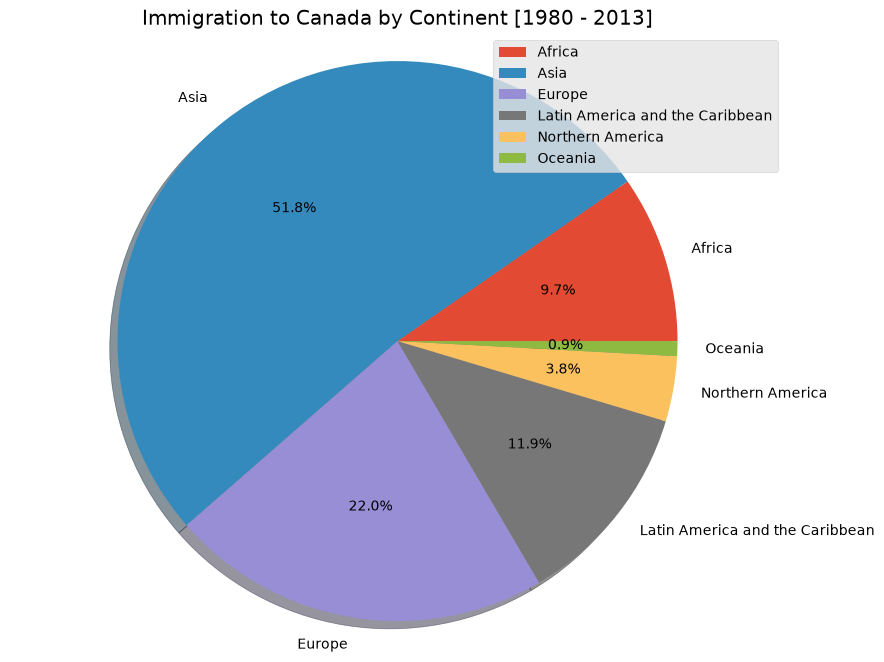

In [13]:
# autopct create %, start angle represent starting point
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 8),
    autopct="%1.1f%%",  # tambahkan dalam persentase
    shadow=True,
)

plt.title("Immigration to Canada by Continent [1980 - 2013]")
plt.axis(
    "equal"
)  # Mengatur tampilan diagram lingkaran agar menyerupai bentuk lingkaran.
plt.legend(labels=df_continents.index, loc="upper right")

plt.savefig("../outputs/pie_chart_without_explode.png", dpi=200, bbox_inches="tight")
plt.show()

Visual di atas kurang jelas, angka dan teks tumpang tindih di beberapa bagian. Mari kita lakukan beberapa modifikasi untuk meningkatkan visualnya:

*   Hapus label teks pada diagram lingkaran dengan memberikan parameter `legend` dan tambahkan sebagai legenda terpisah menggunakan `plt.legend()`.
*   Geser persentase agar berada tepat di luar diagram lingkaran dengan memberikan parameter `pctdistance`.
*   Masukkan serangkaian warna khusus untuk benua dengan memberikan parameter `colors`.
*   **Explode** diagram lingkaran tersebut digunakan untuk menekankan tiga benua terendah (Afrika, Amerika Utara, dan Amerika Latin serta Karibia) dengan memasukkan parameter `explode`


In [14]:
color_list = ["gold", "yellowgreen", "lightcoral", "lightskyblue", "lightgreen", "pink"]
explode_list = [
    0.1,
    0,
    0,
    0,
    0.1,
    0.1,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

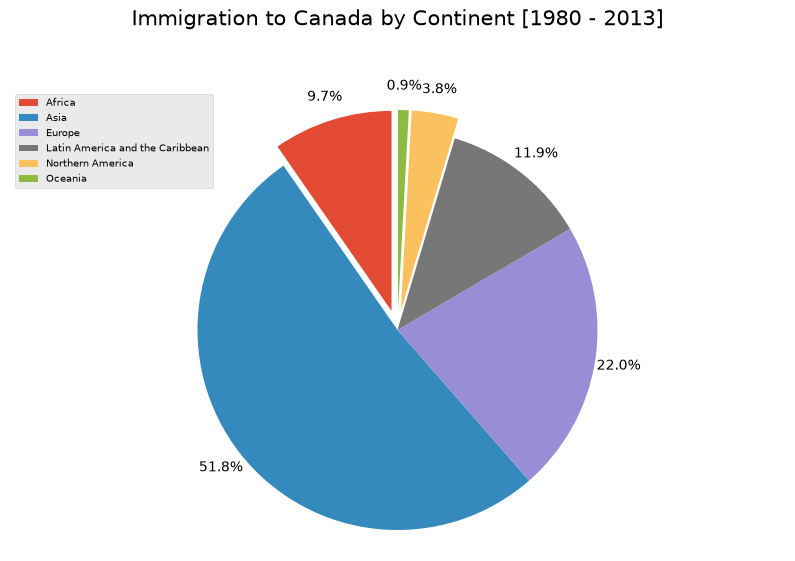

In [15]:
# Buat plot
df_continents["Total"].plot(
    kind="pie",
    figsize=(10, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,  # matikan label pada diagram lingkaran
    pctdistance=1.12,  # rasio antara pusat setiap irisan pai dan awal teks yang dihasilkan oleh autopct
    color=color_list,  # tambahkan warna khusus
    explode=explode_list,  # 'explode' di 3 benua terendah
)

# Perbesar ukuran judul sebesar 12% agar sesuai dengan pctdistance.
plt.title("Immigration to Canada by Continent [1980 - 2013]", y=1.12, fontsize=15)

plt.axis("equal")

# tambahkan legenda
plt.legend(labels=df_continents.index, loc="upper left", fontsize=7)

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent.png", dpi=200, bbox_inches="tight"
)
plt.show()

**Pertanyaan:** Dengan menggunakan diagram lingkaran, jelaskan proporsi (persentase) imigran baru yang dikelompokkan berdasarkan benua pada tahun 2013.

**Catatan**: Anda mungkin perlu bereksperimen dengan nilai eksplorasi untuk memperbaiki nilai irisan yang tumpang tindih.


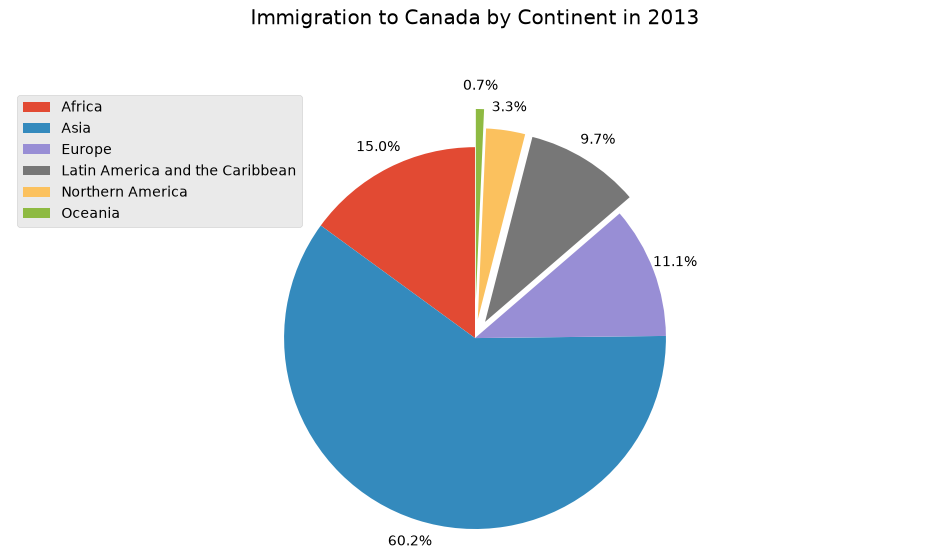

In [16]:
explode_list2 = [
    0.0,
    0,
    0,
    0.1,
    0.1,
    0.2,
]  # rasio untuk setiap benua yang digunakan untuk mengimbangi setiap irisan.

# Buat plot
df_continents["2013"].plot(
    kind="pie",
    figsize=(12, 6),
    autopct="%1.1f%%",
    startangle=90,
    labels=None,
    pctdistance=1.12,
    explode=explode_list2,
)

plt.title("Immigration to Canada by Continent in 2013", y=1.12)
plt.axis("equal")

plt.legend(labels=df_continents.index, loc="upper left")

plt.savefig(
    "../outputs/pie_charts_immigration_by_continent_2013.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Box Plots <a id="8"></a>

`Box plot` adalah cara untuk merepresentasikan *distribusi* data secara statistik melalui lima dimensi utama:

*   **Minimum:** Angka terkecil dalam dataset, tidak termasuk outlier.
*   **First quartile:** Angka tengah antara nilai `minimum` dan nilai `median`.
*   **Second quartile (Median):** Angka tengah dari dataset (yang sudah diurutkan).
*   **Third quartile:** Angka tengah antara `median` dan `maksimum`.
*   **Maximum:** Angka terbesar dalam dataset, tidak termasuk outlier.


<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/boxplot_complete.png" width="440," align="center">


Untuk membuat `boxplot`, kita dapat menggunakan `kind=box` dalam metode `plot` yang dipanggil pada series atau dataframe *pandas*.

Mari kita buat diagram kotak untuk imigran Jepang antara tahun 1980 - 2013.


Langkah 1: Dapatkan subset dari dataset. Meskipun kita hanya mengekstrak data untuk satu negara, kita akan memperolehnya sebagai dataframe. Ini akan membantu kita dalam memanggil metode `dataframe.describe()` untuk melihat persentilnya.


In [17]:
df_japan = df_canada.loc[["Japan"], years].transpose()
df_japan.head()

,Japan
1980,701
1981,756
1982,598
1983,309
1984,246


Langkah 2: Plot dengan memasukkan `kind='box'`.


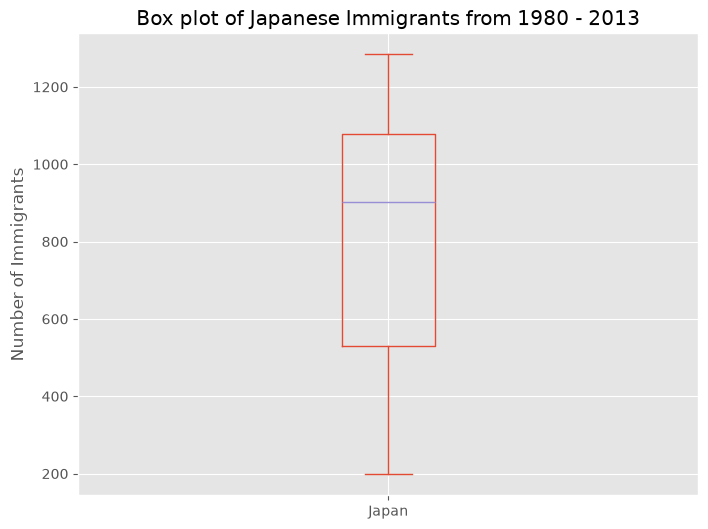

In [18]:
df_japan.plot(kind="box", figsize=(8, 6))

plt.title("Box plot of Japanese Immigrants from 1980 - 2013")
plt.ylabel("Number of Immigrants")

plt.savefig("../outputs/box_plot_japan_immigrants.png", dpi=200, bbox_inches="tight")
plt.show()

Dari grafik di atas, kita dapat langsung membuat beberapa pengamatan penting:

1.  Jumlah imigran minimum sekitar 200 (min), jumlah maksimum sekitar 1300 (max), dan jumlah imigran median sekitar 900 (median).
2.  25% dari tahun-tahun dalam periode 1980 - 2013 memiliki jumlah imigran tahunan sekitar 500 orang atau kurang (Kuartil pertama).
3.  75% dari tahun-tahun dalam periode 1980 - 2013 memiliki jumlah imigran tahunan sekitar 1100 atau kurang (Kuartil ketiga).

Kita dapat melihat angka sebenarnya dengan memanggil metode `describe()` pada dataframe.

In [19]:
df_japan.describe()

,Japan
count,34.000000
mean,814.911765
std,337.219771
min,198.000000
25%,529.000000
50%,902.000000
75%,1079.000000
max,1284.000000


Salah satu manfaat utama dari box plot adalah untuk membandingkan distribusi beberapa dataset. Pada salah satu praktikum sebelumnya, kita mengamati bahwa China dan India memiliki tren imigrasi yang sangat mirip. Mari kita analisis kedua negara ini lebih lanjut menggunakan box plot.

**Pertanyaan:** Bandingkan distribusi jumlah imigran baru dari China dan India untuk periode 1980 - 2013.

Langkah 1: Dapatkan dataset untuk China dan India dan beri nama dataframe tersebut **df_CI**.

In [20]:
df_CI = df_canada.loc[["China", "India"], years].transpose()
df_CI.head()

,China,India
1980,5123,8880
1981,6682,8670
1982,3308,8147
1983,1863,7338
1984,1527,5704


Mari kita lihat persentil yang terkait dengan kedua negara menggunakan metode `describe()`.

In [21]:
df_CI.describe()

,China,India
count,34.000000,34.000000
mean,19410.647059,20350.117647
std,13568.230790,10007.342579
min,1527.000000,4211.000000
25%,5512.750000,10637.750000
50%,19945.000000,20235.000000
75%,31568.500000,28699.500000
max,42584.000000,36210.000000


Langkah 2: Plot data.

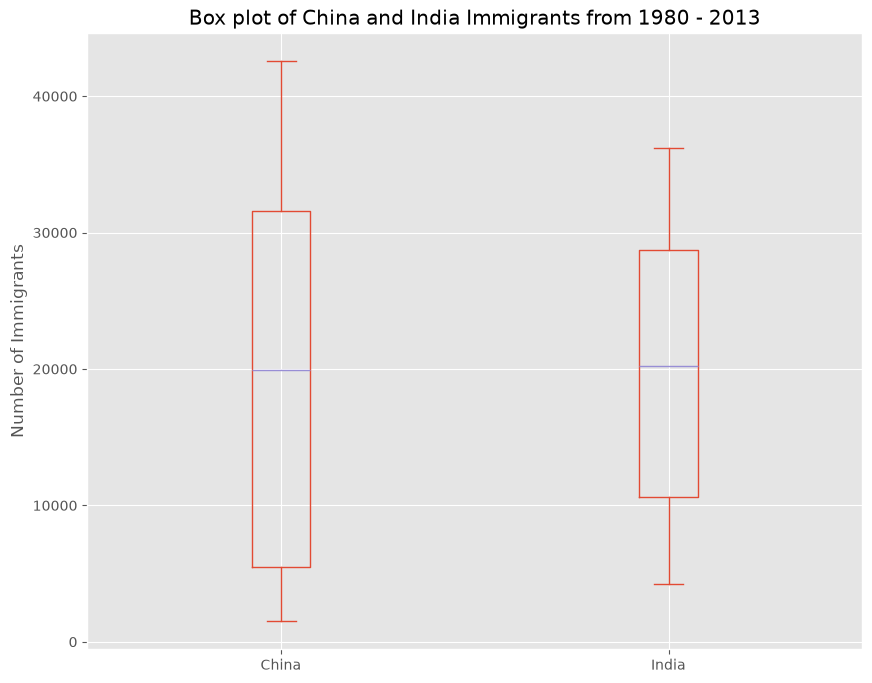

In [22]:
df_CI.plot(kind="box", figsize=(10, 8))

plt.title("Box plot of China and India Immigrants from 1980 - 2013")
plt.ylabel("Number of Immigrants")

plt.savefig("../outputs/box_plot_china_india_immigrants.png", dpi=200, bbox_inches="tight")
plt.show()

Kita dapat mengamati bahwa, meskipun kedua negara memiliki jumlah imigran rata-rata yang hampir sama (~20.000), sebaran populasi imigran di China lebih luas daripada di India. Populasi maksimum dari India untuk tahun tertentu (36.210) sekitar 15% lebih rendah daripada populasi maksimum dari China (42.584).

Jika Anda lebih suka membuat plot kotak horizontal, Anda dapat memberikan parameter `vert` pada fungsi **plot** dan menetapkannya ke *False*. Anda juga dapat menentukan warna yang berbeda jika Anda tidak menyukai warna merah default.

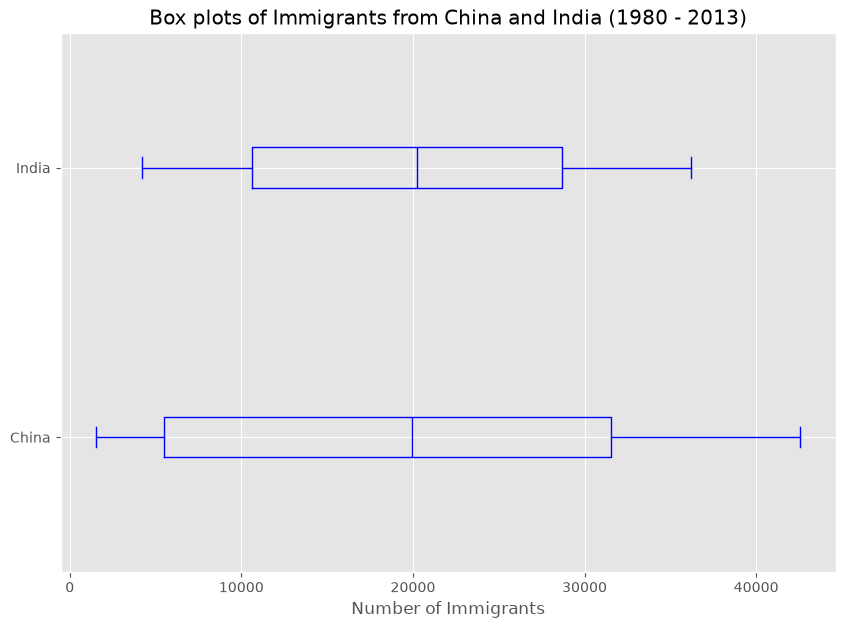

In [23]:
df_CI.plot(kind="box", figsize=(10, 7), color="blue", vert=False)

plt.title("Box plots of Immigrants from China and India (1980 - 2013)")
plt.xlabel("Number of Immigrants")

plt.savefig("../outputs/horizontal_box_plot.png", dpi=200, bbox_inches="tight")
plt.show()

**Subplots**

Seringkali kita mungkin ingin menampilkan beberapa plot dalam satu gambar yang sama. Misalnya, kita mungkin ingin melakukan perbandingan berdampingan antara box plot dan line plot imigrasi China dan India.

Untuk memvisualisasikan beberapa plot secara bersamaan, kita dapat membuat **`figure`** (kanvas keseluruhan) dan membaginya menjadi **`subplots`**, yang masing-masing berisi satu plot. Dengan **subplots**, kita biasanya bekerja dengan **artist layer** alih-alih **scripting layer**.

Sintaks tipikalnya adalah : <br>

```python
    fig = plt.figure() # create figure
    ax = fig.add_subplot(nrows, ncols, plot_number) # create subplots
```

Dimana

*   `nrows` dan `ncols` digunakan untuk membagi gambar secara konseptual menjadi (`nrows` * `ncols`) sub-axes,
*   `plot_number` digunakan untuk mengidentifikasi subplot tertentu yang akan dibuat oleh fungsi ini di dalam grid hipotetis. `plot_number` dimulai dari 1, bertambah secara berurutan di setiap baris, dan memiliki nilai maksimum `nrows` * `ncols` seperti yang ditunjukkan di bawah ini.

<img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/Module%203/images/Mod3Fig5Subplots_V2.png" width="500" align="center">


Kita kemudian dapat menentukan subplot mana tempat setiap plot akan ditempatkan dengan memberikan parameter `ax` pada metode `plot()` sebagai berikut:

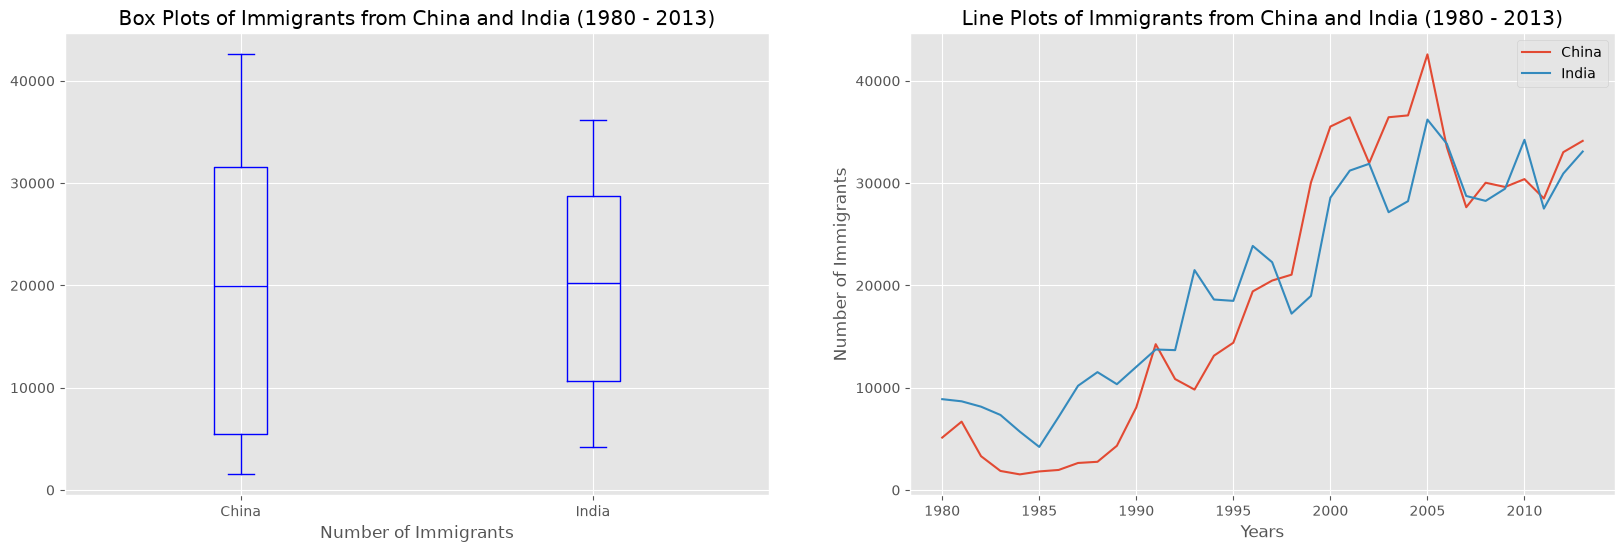

In [24]:
fig = plt.figure() # create figure

ax0 = fig.add_subplot(1, 2, 1) # add subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2) # add subplot 2 (1 row, 2 columns, second plot)

# Subplot 1: Box Plot
df_CI.plot(kind="box", figsize=(20, 6), color="blue", ax=ax0)
ax0.set_title("Box Plots of Immigrants from China and India (1980 - 2013)")
ax0.set_xlabel("Number of Immigrants")
ax1.set_ylabel("Countries")

# Subplot 2: Line Plot
df_CI.plot(kind="line", figsize=(20, 6), ax=ax1)
ax1.set_title("Line Plots of Immigrants from China and India (1980 - 2013)")
ax1.set_ylabel("Number of Immigrants")
ax1.set_xlabel("Years")

plt.savefig("../outputs/subplots_immigrant_china_india.png", dpi=200, bbox_inches="tight")
plt.show()

**Tips mengenai konvensi subplot**

Dalam kasus di mana `nrows`, `ncols`, dan `plot_number` semuanya kurang dari 10, ada cara mudah untuk memberikan angka 3 digit sebagai gantinya, di mana ratusan mewakili `nrows`, puluhan mewakili `ncols`, dan satuan mewakili `plot_number`. Misalnya,

```python
   subplot(211) == subplot(2, 1, 1) 
```

menghasilkan sub-axes dalam sebuah gambar yang mewakili plot teratas (yaitu yang pertama) dalam grid imajiner 2 baris kali 1 kolom (tidak ada grid yang sebenarnya ada, tetapi secara konseptual begitulah posisi sub-plot yang dikembalikan).


Mari kita coba sesuatu yang sedikit lebih canggih.

Sebelumnya kami telah mengidentifikasi 15 negara teratas berdasarkan total imigrasi dari tahun 1980 - 2013.

**Pertanyaan:** Buatlah diagram kotak (box plot) untuk memvisualisasikan distribusi 15 negara teratas (berdasarkan total imigrasi) yang dikelompokkan menurut *dekade* `1980-an`, `1990-an`, dan `2000-an`.


Langkah 1: Dapatkan dataset. Dapatkan 15 negara teratas berdasarkan total populasi imigran. Beri nama dataframe **df_top15**.

In [25]:
df_canada.sort_values("Total", axis=0, ascending=False, inplace=True)

df_top15 = df_canada.head(15)
df_top15

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,7150,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904
China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,1960,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
United Kingdom of Great Britain and Northern Ireland,Europe,Northern Europe,Developed regions,22045,24796,20620,10015,10170,9564,9470,...,7258,7140,8216,8979,8876,8724,6204,6195,5827,551500
Philippines,Asia,South-Eastern Asia,Developing regions,6051,5921,5249,4562,3801,3150,4166,...,18139,18400,19837,24887,28573,38617,36765,34315,29544,511391
Pakistan,Asia,Southern Asia,Developing regions,978,972,1201,900,668,514,691,...,14314,13127,10124,8994,7217,6811,7468,11227,12603,241600
United States of America,Northern America,Northern America,Developed regions,9378,10030,9074,7100,6661,6543,7074,...,8394,9613,9463,10190,8995,8142,7676,7891,8501,241122
Iran (Islamic Republic of),Asia,Southern Asia,Developing regions,1172,1429,1822,1592,1977,1648,1794,...,5837,7480,6974,6475,6580,7477,7479,7534,11291,175923
Sri Lanka,Asia,Southern Asia,Developing regions,185,371,290,197,1086,845,1838,...,4930,4714,4123,4756,4547,4422,3309,3338,2394,148358
Republic of Korea,Asia,Eastern Asia,Developing regions,1011,1456,1572,1081,847,962,1208,...,5832,6215,5920,7294,5874,5537,4588,5316,4509,142581
Poland,Europe,Eastern Europe,Developed regions,863,2930,5881,4546,3588,2819,4808,...,1405,1263,1235,1267,1013,795,720,779,852,139241


Langkah 2: Buat dataframe baru yang berisi agregat untuk setiap dekade. Salah satu caranya adalah:

1.  Buatlah daftar semua tahun dalam dekade 80-an, 90-an, dan 00-an.
2.  Iris dataframe asli df_top15 untuk membuat rangkaian data untuk setiap dekade dan jumlahkan semua data untuk setiap negara selama bertahun-tahun.
3.  Gabungkan ketiga series tersebut ke dalam data frame baru. Beri nama data frame Anda **new_df**.

In [26]:
# 1: Buat daftar semua tahun dalam dekade
years_80s = list(map(str, range(1980, 1990)))
years_90s = list(map(str, range(1990, 2000)))
years_00s = list(map(str, range(2000, 2010)))

In [27]:
# 2: Potong dataframe asli df_top15 untuk membuat series untuk setiap dekade.
df_80s = df_top15.loc[:, years_80s].sum(axis=1)
df_90s = df_top15.loc[:, years_90s].sum(axis=1)
df_00s = df_top15.loc[:, years_00s].sum(axis=1)

In [28]:
# 3: Gabungkan ketiga series tersebut ke dalam dataframe baru
new_df = pd.DataFrame({
    "1980s": df_80s,
    "1990s": df_90s,
    "2000s": df_00s
})

In [29]:
new_df

,1980s,1990s,2000s
India,82154,180395,303591
China,32003,161528,340385
United Kingdom of Great Britain and Northern Ireland,179171,261966,83413
Philippines,60764,138482,172904
Pakistan,10591,65302,127598
United States of America,76824,56915,75173
Iran (Islamic Republic of),21477,54871,65794
Sri Lanka,14796,70421,49678
Republic of Korea,16259,38189,68183
Poland,57602,64864,13629


Mari kita pelajari lebih lanjut tentang statistik yang terkait dengan dataframe menggunakan metode `describe()`.


In [30]:
new_df.describe()

,1980s,1990s,2000s
count,15.000000,15.000000,15.000000
mean,44418.333333,85594.666667,97471.533333
std,44190.676455,68237.560246,100583.204205
min,7613.000000,30028.000000,13629.000000
25%,16698.000000,39259.000000,36101.500000
50%,30638.000000,56915.000000,65794.000000
75%,59183.000000,104451.500000,105505.500000
max,179171.000000,261966.000000,340385.000000


Langkah 3: Buat box plot.

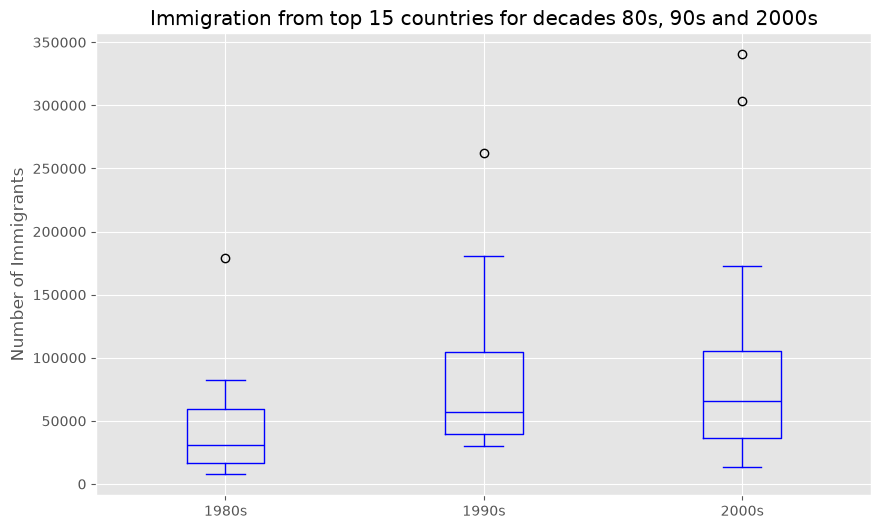

In [31]:
new_df.plot(kind="box", figsize=(10, 6), color="blue")

plt.title("Immigration from top 15 countries for decades 80s, 90s and 2000s")
plt.ylabel("Number of Immigrants")

plt.savefig("../outputs/box_plot_top_15_immigrant.png", dpi=200, bbox_inches="tight")
plt.show()

Perhatikan bagaimana box plot berbeda dari tabel ringkasan yang dibuat. Box plot memindai data dan mengidentifikasi data outlier. Agar menjadi data outlier, nilai data harus:<br>

*   lebih besar dari Q3 setidaknya 1,5 kali rentang interkuartil (IQR), atau,
*   lebih kecil dari Q1 setidaknya 1,5 kali IQR.

Mari kita ambil dekade 2000-an sebagai contoh: <br>

*   Q1 (25%) = 36,101.5 <br>
*   Q3 (75%) = 105,505.5 <br>
*   IQR = Q3 - Q1 = 69,404 <br>

Berdasarkan definisi outlier, setiap nilai yang lebih besar dari Q3 sebesar 1,5 kali IQR akan ditandai sebagai outlier.

Outlier > 105,505.5 + (1.5 \* 69,404) <br>
Outlier > 209,611.5


In [32]:
# mari kita periksa berapa banyak entri yang berada di atas ambang batas outlier.
new_df=new_df.reset_index()
new_df[new_df["2000s"] > 209611.5]

,index,1980s,1990s,2000s
0,India,82154,180395,303591
1,China,32003,161528,340385


China dan India sama-sama dianggap sebagai outliers karena populasi mereka selama dekade tersebut melebihi 209.611,5 jiwa.

Diagram kotak (box plot) adalah alat visualisasi tingkat lanjut, dan terdapat banyak pilihan dan penyesuaian yang melampaui cakupan praktikum ini. Silakan merujuk ke [Matplotlib documentation](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.boxplot.html) untuk informasi lebih lanjut.